# Credit Risk Analysis & Application Scorecard

**Author:** Prathamesh Tirshu  
**Tools:** Python (Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn)  
**Dataset:** German Credit Data (1,000 loan applicants, 20 attributes) — a widely used public credit-risk dataset originally from the UCI Machine Learning Repository.

## Business problem
A lender wants to decide which loan applications to approve. Approving a borrower who later defaults costs money; rejecting a good borrower loses interest income.

**Goal:** find which applicant characteristics drive default risk, and build a simple, explainable, points-based **credit scorecard** that the credit team can use to approve, review or reject applications.

## Approach
1. Data understanding & quality checks  
2. Exploratory analysis — default rate by applicant segment  
3. Feature selection using **Weight of Evidence (WoE)** and **Information Value (IV)**  
4. **Logistic Regression** model on WoE-transformed features  
5. Model evaluation — AUC, Gini, KS statistic, confusion matrix  
6. Convert model output into **scorecard points** and **risk bands**  
7. Approval cut-off analysis & business recommendations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report

pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')
CHARTS = 'outputs/charts/'

## 1. Load and understand the data

In [2]:
df = pd.read_csv('data/german_credit.csv')
print('Shape:', df.shape)
df.head()

Shape: (1000, 21)


,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,present_residence,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,... < 100 DM,6,critical account/other credits existing,domestic appliances,1169,unknown/no savings account,... >= 7 years,4,male : single,none,4,real estate,67,none,own,2,skilled employee/official,1,yes,yes,1
1,0 <= ... < 200 DM,48,existing credits paid back duly till now,domestic appliances,5951,... < 100 DM,1 <= ... < 4 years,2,female : divorced/separated/married,none,2,real estate,22,none,own,1,skilled employee/official,1,no,yes,0
2,no checking account,12,critical account/other credits existing,retraining,2096,... < 100 DM,4 <= ... < 7 years,2,male : single,none,3,real estate,49,none,own,1,unskilled - resident,2,no,yes,1
3,... < 100 DM,42,existing credits paid back duly till now,radio/television,7882,... < 100 DM,4 <= ... < 7 years,2,male : single,guarantor,4,building society savings agreement/life insurance,45,none,for free,1,skilled employee/official,2,no,yes,1
4,... < 100 DM,24,delay in paying off in the past,car (new),4870,... < 100 DM,1 <= ... < 4 years,3,male : single,none,4,unknown/no property,53,none,for free,2,skilled employee/official,2,no,yes,0


The target column `credit_risk` is **1 = good** (repaid) and **0 = bad** (defaulted).  
For risk analysis it is easier to work with a **default flag**, so we create `default = 1` for bad borrowers.

In [3]:
df['default'] = 1 - df['credit_risk']
df = df.drop(columns='credit_risk')

print('Overall default rate: {:.1%}'.format(df['default'].mean()))
df['default'].value_counts().rename({0: 'Good (0)', 1: 'Default (1)'})

Overall default rate: 30.0%


default
Good (0)       700
Default (1)    300
Name: count, dtype: int64

### Data quality checks

In [4]:
quality = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing': df.isna().sum(),
    'unique_values': df.nunique()
})
print('Duplicate rows:', df.duplicated().sum())
quality

Duplicate rows: 0


,dtype,missing,unique_values
status,str,0,4
duration,int64,0,33
credit_history,str,0,5
purpose,str,0,10
amount,int64,0,921
savings,str,0,5
employment_duration,str,0,5
installment_rate,int64,0,4
personal_status_sex,str,0,4
other_debtors,str,0,3


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
duration,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
amount,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
installment_rate,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
present_residence,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
age,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
number_credits,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
people_liable,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0
default,1000.0,0.300,0.458487,0.0,0.0,0.0,1.00,1.0


**Observations:** no missing values and no duplicates, so no imputation is needed.  
Numeric fields: `duration` (months), `amount` (loan amount in DM), `age`, `installment_rate`, `present_residence`, `number_credits`, `people_liable`.  
The rest are categorical attributes such as checking-account status, credit history, purpose and savings.

## 2. Exploratory analysis — what drives default?

In [6]:
def default_rate_by(col, data=df):
    t = data.groupby(col, observed=True)['default'].agg(applicants='count', defaults='sum', default_rate='mean')
    return t.sort_values('default_rate', ascending=False)

default_rate_by('status')

,applicants,defaults,default_rate
status,,,
... < 100 DM,274,135,0.492701
0 <= ... < 200 DM,269,105,0.390335
... >= 200 DM / salary for at least 1 year,63,14,0.222222
no checking account,394,46,0.116751


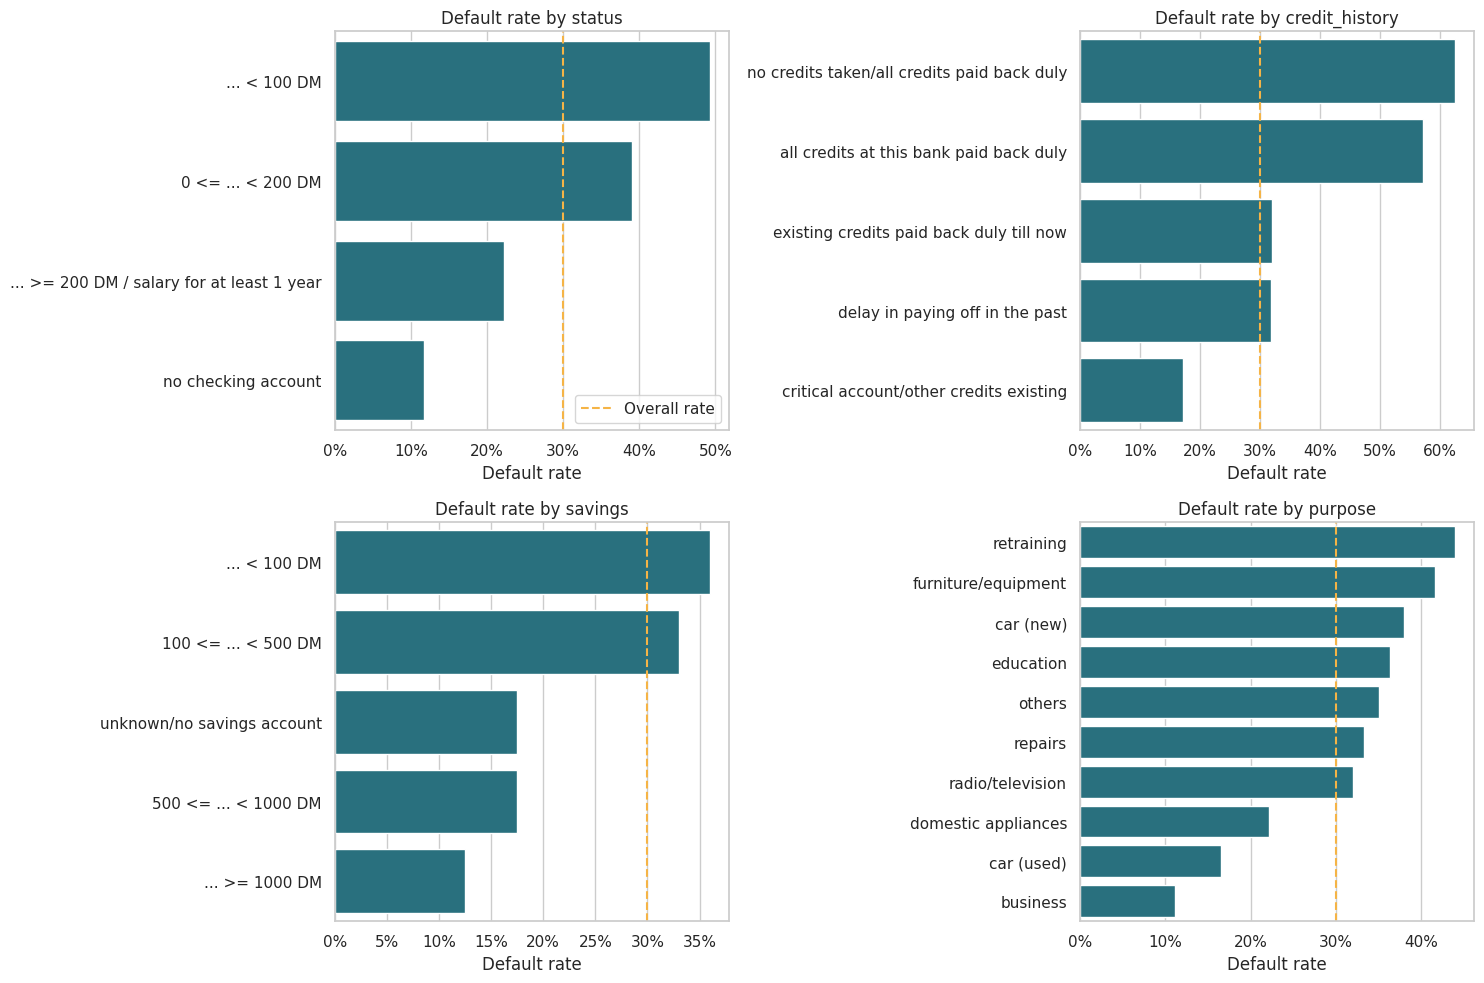

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, col in zip(axes.ravel(), ['status', 'credit_history', 'savings', 'purpose']):
    t = default_rate_by(col).reset_index()
    sns.barplot(data=t, y=col, x='default_rate', ax=ax, color='#1B7A8C')
    ax.axvline(df['default'].mean(), color='#F5B446', ls='--', label='Overall rate')
    ax.set_title(f'Default rate by {col}'); ax.set_xlabel('Default rate'); ax.set_ylabel('')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
axes[0, 0].legend()
plt.tight_layout(); plt.savefig(CHARTS + '01_default_rate_by_category.png', dpi=120); plt.show()

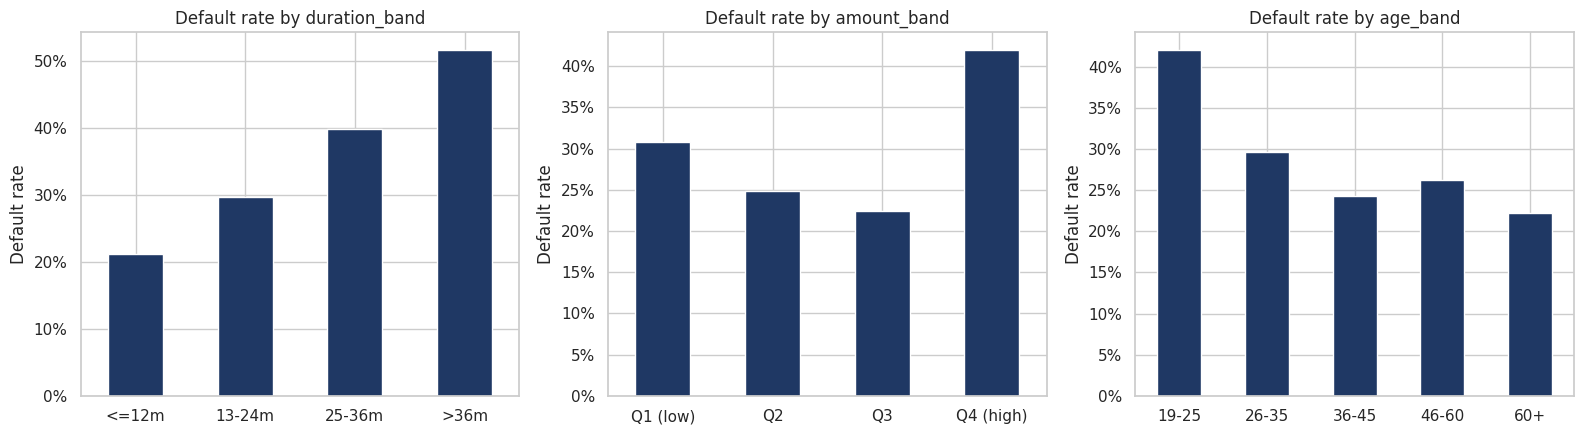

{'<=12m': 0.212, '13-24m': 0.297, '25-36m': 0.399, '>36m': 0.517}
{'Q1 (low)': 0.308, 'Q2': 0.248, 'Q3': 0.224, 'Q4 (high)': 0.42}
{'19-25': 0.421, '26-35': 0.296, '36-45': 0.243, '46-60': 0.262, '60+': 0.222}


In [8]:
# Bucket the numeric variables to see the risk trend
df['duration_band'] = pd.cut(df['duration'], [0, 12, 24, 36, 72], labels=['<=12m', '13-24m', '25-36m', '>36m'])
df['amount_band'] = pd.qcut(df['amount'], 4, labels=['Q1 (low)', 'Q2', 'Q3', 'Q4 (high)'])
df['age_band'] = pd.cut(df['age'], [18, 25, 35, 45, 60, 80], labels=['19-25', '26-35', '36-45', '46-60', '60+'])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ['duration_band', 'amount_band', 'age_band']):
    t = df.groupby(col, observed=True)['default'].mean()
    t.plot(kind='bar', ax=ax, color='#1F3864')
    ax.set_title(f'Default rate by {col}'); ax.set_ylabel('Default rate'); ax.set_xlabel('')
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}')); ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.savefig(CHARTS + '02_default_rate_by_numeric_bands.png', dpi=120); plt.show()

for col in ['duration_band', 'amount_band', 'age_band']:
    print(df.groupby(col, observed=True)['default'].mean().round(3).to_dict())

**Key EDA findings** (see numbers above):
- Applicants with a **negative checking-account balance (`... < 0 DM`)** default far more often than those with no checking account.
- **Longer loans are riskier**: default rate rises steadily with loan duration.
- The **largest loans (top quartile)** carry the highest default risk.
- **Younger applicants (19–25)** show the highest default rate.
- Savings and credit history are also strong separators.

## 3. Feature selection — Weight of Evidence (WoE) & Information Value (IV)

WoE and IV are the standard tools in credit scoring:

- **WoE** for a bin = ln( % of goods in the bin / % of bads in the bin ). Negative WoE = riskier than average.
- **IV** = Σ (%goods − %bads) × WoE. It measures how well a variable separates good and bad borrowers.

| IV | Predictive power |
|---|---|
| < 0.02 | Not useful |
| 0.02 – 0.1 | Weak |
| 0.1 – 0.3 | Medium |
| 0.3 – 0.5 | Strong |
| > 0.5 | Very strong — check it is not leaking future information |

In [9]:
numeric_cols = ['duration', 'amount', 'age']
categorical_cols = ['status', 'credit_history', 'purpose', 'savings', 'employment_duration',
                    'installment_rate', 'personal_status_sex', 'other_debtors', 'present_residence',
                    'property', 'other_installment_plans', 'housing', 'number_credits', 'job',
                    'people_liable', 'telephone', 'foreign_worker']

# Bin numeric variables into 5 quantile groups; categorical variables keep their own categories
binned = pd.DataFrame(index=df.index)
for c in numeric_cols:
    binned[c] = pd.qcut(df[c], 5, duplicates='drop').astype(str)
for c in categorical_cols:
    binned[c] = df[c].astype(str)
binned['default'] = df['default']

def woe_iv(data, feature, target='default', eps=0.5):
    g = data.groupby(feature)[target].agg(total='count', bad='sum')
    g['good'] = g['total'] - g['bad']
    # eps avoids division by zero for bins with no goods or no bads
    g['dist_good'] = (g['good'] + eps) / (g['good'].sum() + eps)
    g['dist_bad'] = (g['bad'] + eps) / (g['bad'].sum() + eps)
    g['woe'] = np.log(g['dist_good'] / g['dist_bad'])
    g['iv'] = (g['dist_good'] - g['dist_bad']) * g['woe']
    return g, g['iv'].sum()

woe_tables, iv = {}, {}
for c in numeric_cols + categorical_cols:
    woe_tables[c], iv[c] = woe_iv(binned, c)

iv_table = pd.Series(iv).sort_values(ascending=False).rename('IV').to_frame()
iv_table['power'] = pd.cut(iv_table['IV'], [-1, 0.02, 0.1, 0.3, 0.5, 10],
                           labels=['Not useful', 'Weak', 'Medium', 'Strong', 'Very strong'])
iv_table.round(3)

,IV,power
status,0.661,Very strong
credit_history,0.292,Medium
duration,0.214,Medium
savings,0.189,Medium
purpose,0.165,Medium
property,0.112,Medium
amount,0.093,Weak
employment_duration,0.086,Weak
housing,0.084,Weak
age,0.068,Weak


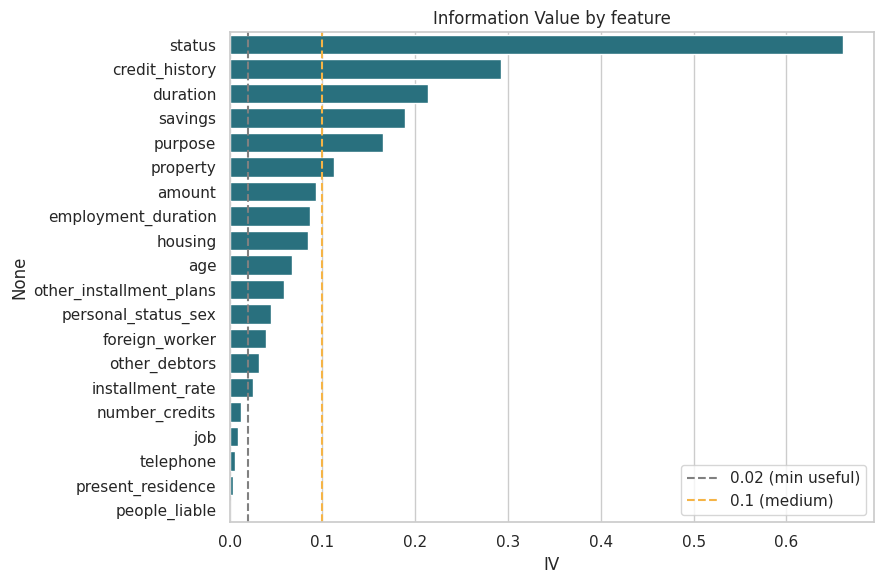

In [10]:
plt.figure(figsize=(9, 6))
sns.barplot(x=iv_table['IV'], y=iv_table.index, color='#1B7A8C')
plt.axvline(0.02, color='grey', ls='--', label='0.02 (min useful)')
plt.axvline(0.1, color='#F5B446', ls='--', label='0.1 (medium)')
plt.title('Information Value by feature'); plt.legend(); plt.tight_layout()
plt.savefig(CHARTS + '03_information_value.png', dpi=120); plt.show()

`status` (checking-account balance) has IV above 0.5. A very high IV can signal **data leakage** (a field that is only known *after* the outcome). Here it is fine: the checking-account balance is known **at the time of application**, so it is a genuine, legitimate predictor.

We keep every feature with **IV ≥ 0.02** and drop the rest (job, telephone, residence length, etc.) because they add noise without adding predictive power.

In [11]:
# Keep features with IV >= 0.02
selected = iv_table[iv_table['IV'] >= 0.02].index.tolist()
print(len(selected), 'features selected:', selected)
woe_tables['status'][['total', 'bad', 'woe']].round(3)

15 features selected: ['status', 'credit_history', 'duration', 'savings', 'purpose', 'property', 'amount', 'employment_duration', 'housing', 'age', 'other_installment_plans', 'personal_status_sex', 'foreign_worker', 'other_debtors', 'installment_rate']


,total,bad,woe
status,,,
... < 100 DM,274,135,-0.817
... >= 200 DM / salary for at least 1 year,63,14,0.381
0 <= ... < 200 DM,269,105,-0.402
no checking account,394,46,1.168


## 4. Logistic Regression on WoE features

In [12]:
# Replace every value with its bin's WoE
X = pd.DataFrame({c: binned[c].map(woe_tables[c]['woe']) for c in selected})
y = df['default']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
print('Train:', X_train.shape, ' Test:', X_test.shape)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

coef = pd.Series(model.coef_[0], index=selected).sort_values()
coef.round(3).to_frame('coefficient')

Train: (700, 15)  Test: (300, 15)


,coefficient
installment_rate,-1.283
foreign_worker,-0.995
other_installment_plans,-0.930
savings,-0.883
personal_status_sex,-0.813
employment_duration,-0.800
status,-0.754
duration,-0.708
purpose,-0.682
other_debtors,-0.612


All coefficients should be **negative**: a higher WoE means a "safer" bin, so it should *reduce* the probability of default. Negative signs confirm the model is behaving logically — an important check for a credit model that must be explained to auditors.

## 5. Model evaluation — AUC, Gini, KS

In [13]:
def evaluate(y_true, p):
    auc = roc_auc_score(y_true, p)
    fpr, tpr, _ = roc_curve(y_true, p)
    ks = np.max(tpr - fpr)
    return auc, 2 * auc - 1, ks

p_train = model.predict_proba(X_train)[:, 1]
p_test = model.predict_proba(X_test)[:, 1]

res = pd.DataFrame([evaluate(y_train, p_train), evaluate(y_test, p_test)],
                   index=['Train', 'Test'], columns=['AUC', 'Gini', 'KS']).round(3)
res

,AUC,Gini,KS
Train,0.819,0.638,0.507
Test,0.825,0.651,0.560


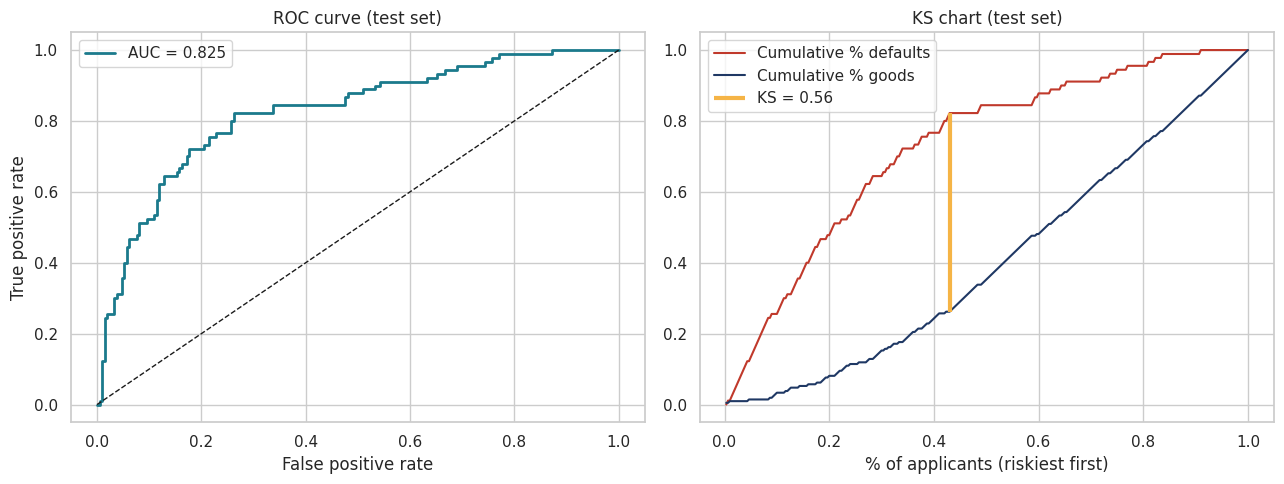

In [14]:
fpr, tpr, _ = roc_curve(y_test, p_test)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(fpr, tpr, color='#1B7A8C', lw=2, label=f'AUC = {roc_auc_score(y_test, p_test):.3f}')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_title('ROC curve (test set)'); axes[0].set_xlabel('False positive rate'); axes[0].set_ylabel('True positive rate'); axes[0].legend()

# KS chart: cumulative % of bads vs goods by predicted risk
order = np.argsort(-p_test)
yt = y_test.values[order]
cum_bad = np.cumsum(yt) / yt.sum(); cum_good = np.cumsum(1 - yt) / (1 - yt).sum()
x = np.arange(1, len(yt) + 1) / len(yt)
axes[1].plot(x, cum_bad, label='Cumulative % defaults', color='#C0392B')
axes[1].plot(x, cum_good, label='Cumulative % goods', color='#1F3864')
k = np.argmax(cum_bad - cum_good)
axes[1].vlines(x[k], cum_good[k], cum_bad[k], color='#F5B446', lw=3, label=f'KS = {cum_bad[k]-cum_good[k]:.2f}')
axes[1].set_title('KS chart (test set)'); axes[1].set_xlabel('% of applicants (riskiest first)'); axes[1].legend()
plt.tight_layout(); plt.savefig(CHARTS + '04_roc_ks.png', dpi=120); plt.show()

In [15]:
# Confusion matrix at the default 0.5 threshold, and at a business threshold of 0.35
for thr in [0.5, 0.35]:
    pred = (p_test >= thr).astype(int)
    print(f'--- Threshold {thr} ---')
    print(pd.DataFrame(confusion_matrix(y_test, pred), index=['Actual good', 'Actual default'],
                       columns=['Pred good', 'Pred default']))
    print(classification_report(y_test, pred, target_names=['Good', 'Default'], digits=3))

--- Threshold 0.5 ---
                Pred good  Pred default
Actual good           193            17
Actual default         45            45
              precision    recall  f1-score   support

        Good      0.811     0.919     0.862       210
     Default      0.726     0.500     0.592        90

    accuracy                          0.793       300
   macro avg      0.768     0.710     0.727       300
weighted avg      0.785     0.793     0.781       300

--- Threshold 0.35 ---
                Pred good  Pred default
Actual good           166            44
Actual default         24            66
              precision    recall  f1-score   support

        Good      0.874     0.790     0.830       210
     Default      0.600     0.733     0.660        90

    accuracy                          0.773       300
   macro avg      0.737     0.762     0.745       300
weighted avg      0.792     0.773     0.779       300



**Reading the results:** Train and test AUC are close, so the model is **not over-fitting**. Test AUC ≈ 0.83, Gini ≈ 0.65 and KS ≈ 0.56 are **good** values for an application scorecard (in industry, Gini above 0.4 and KS above 0.3 are usually considered acceptable).  
Lowering the threshold from 0.5 to 0.35 catches more defaulters (higher recall) at the cost of rejecting some good customers — this trade-off is a **business decision** about risk appetite.

## 6. Convert to a points-based scorecard

Standard scaling used by banks: **600 points = odds of 50:1 (good:bad)**, and every **20 points doubles the odds** (Points to Double the Odds, PDO = 20).

- Factor = PDO / ln(2)  
- Offset = 600 − Factor × ln(50)  
- Score = Offset + Factor × ln(odds of good)

In [16]:
PDO, BASE_SCORE, BASE_ODDS = 20, 600, 50
factor = PDO / np.log(2)
offset = BASE_SCORE - factor * np.log(BASE_ODDS)
n = len(selected)
intercept = model.intercept_[0]

# Points for each attribute bin: higher points = lower risk
rows = []
for c, b in zip(selected, model.coef_[0]):
    for bin_value, woe in woe_tables[c]['woe'].items():
        pts = -(b * woe + intercept / n) * factor + offset / n
        rows.append({'feature': c, 'bin': bin_value, 'woe': round(woe, 3), 'points': round(pts)})
scorecard = pd.DataFrame(rows)
scorecard.to_csv('outputs/scorecard_points.csv', index=False)
scorecard[scorecard['feature'].isin(['status', 'duration'])]

,feature,bin,woe,points
0,status,... < 100 DM,-0.817,16
1,status,... >= 200 DM / salary for at least 1 year,0.381,42
2,status,0 <= ... < 200 DM,-0.402,25
3,status,no checking account,1.168,60
9,duration,"(12.0, 15.0]",0.637,47
10,duration,"(15.0, 24.0]",-0.102,32
11,duration,"(24.0, 30.0]",-0.166,31
12,duration,"(3.999, 12.0]",0.464,44
13,duration,"(30.0, 72.0]",-0.766,19


count    1000.0
mean      520.0
std        40.0
min       426.0
25%       491.0
50%       521.0
75%       549.0
max       647.0
Name: score, dtype: float64


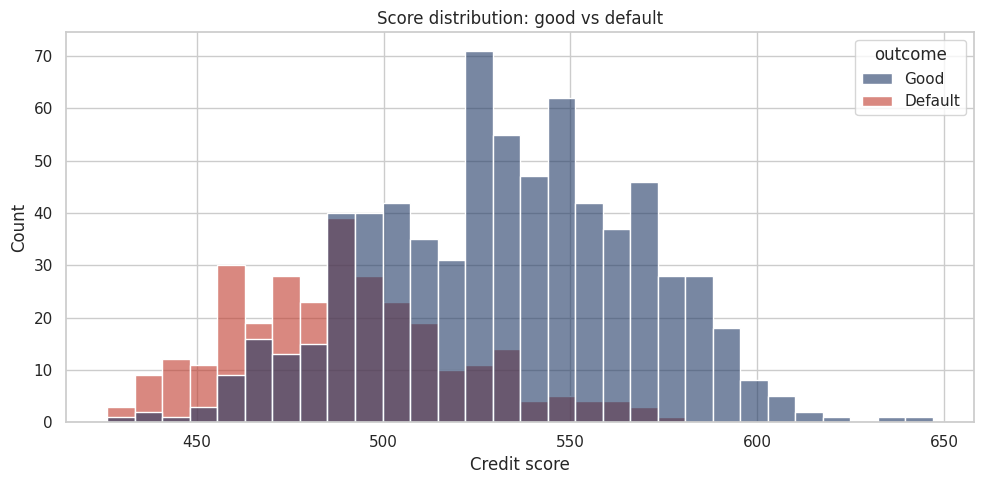

In [17]:
# Score every applicant = sum of points for their bins
def score_applicants(data_binned):
    total = np.zeros(len(data_binned))
    for c in selected:
        pts = scorecard[scorecard['feature'] == c].set_index('bin')['points']
        total += data_binned[c].map(pts).values
    return total

df['score'] = score_applicants(binned)
print(df['score'].describe().round(0))

plt.figure(figsize=(10, 5))
plot_df = df.assign(outcome=df['default'].map({0: 'Good', 1: 'Default'}))
sns.histplot(data=plot_df, x='score', hue='outcome', bins=30, palette={'Good': '#1F3864', 'Default': '#C0392B'}, alpha=0.6)
plt.title('Score distribution: good vs default'); plt.xlabel('Credit score'); plt.tight_layout()
plt.savefig(CHARTS + '05_score_distribution.png', dpi=120); plt.show()

## 7. Risk bands and approval cut-off

In [18]:
df['risk_band'] = pd.qcut(df['score'], 5, labels=['E (very high risk)', 'D (high)', 'C (medium)', 'B (low)', 'A (very low risk)'])
bands = df.groupby('risk_band', observed=True).agg(applicants=('default', 'size'), min_score=('score', 'min'),
                                                   max_score=('score', 'max'), default_rate=('default', 'mean'))
bands['default_rate'] = bands['default_rate'].round(3)
bands

,applicants,min_score,max_score,default_rate
risk_band,,,,
E (very high risk),203,426.0,485.0,0.675
D (high),198,486.0,506.0,0.434
C (medium),204,507.0,531.0,0.225
B (low),196,532.0,556.0,0.112
A (very low risk),199,557.0,647.0,0.045


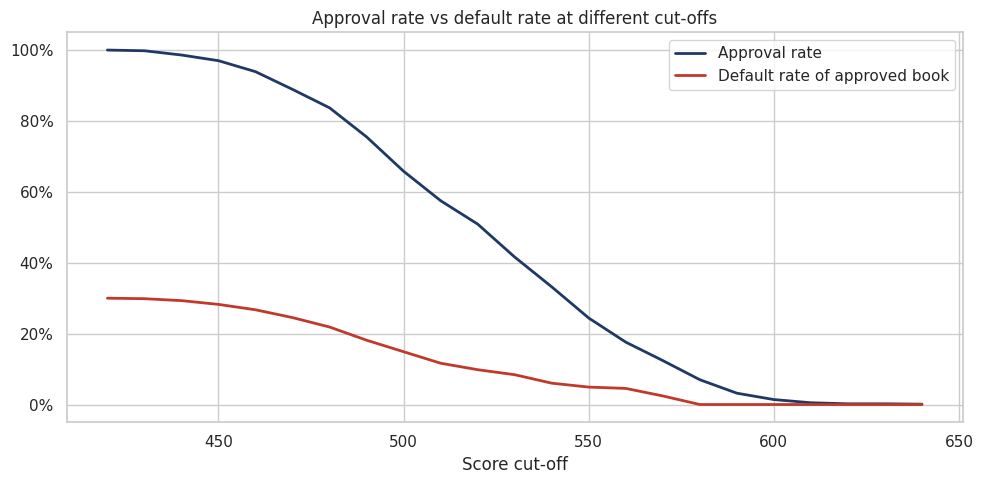

,cut_off,approval_rate,bad_rate_of_approved
0,420,1.000,0.300
2,440,0.986,0.293
4,460,0.939,0.267
6,480,0.837,0.219
8,500,0.658,0.149
10,520,0.509,0.098
12,540,0.332,0.060
14,560,0.176,0.045
16,580,0.070,0.000
18,600,0.014,0.000


In [19]:
cutoffs = []
for cut in np.arange(int(df['score'].min()) // 10 * 10, int(df['score'].max()), 10):
    approved = df[df['score'] >= cut]
    cutoffs.append({'cut_off': cut, 'approval_rate': len(approved) / len(df),
                    'bad_rate_of_approved': approved['default'].mean() if len(approved) else np.nan})
cutoffs = pd.DataFrame(cutoffs)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(cutoffs['cut_off'], cutoffs['approval_rate'], label='Approval rate', color='#1F3864', lw=2)
ax.plot(cutoffs['cut_off'], cutoffs['bad_rate_of_approved'], label='Default rate of approved book', color='#C0392B', lw=2)
ax.set_xlabel('Score cut-off'); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_title('Approval rate vs default rate at different cut-offs'); ax.legend()
plt.tight_layout(); plt.savefig(CHARTS + '06_cutoff_tradeoff.png', dpi=120); plt.show()

cutoffs.round(3).iloc[::2]

In [20]:
# Example: choose the cut-off that keeps the approved book's default rate at or below 20%
target = 0.20
ok = cutoffs[cutoffs['bad_rate_of_approved'] <= target].iloc[0]
print(f"Cut-off {ok['cut_off']:.0f}: approve {ok['approval_rate']:.0%} of applicants, "
      f"default rate of approved loans {ok['bad_rate_of_approved']:.1%} (vs {df['default'].mean():.0%} if we approve everyone)")

df[['score', 'risk_band', 'default']].to_csv('outputs/scored_applicants.csv', index=False)

Cut-off 490: approve 76% of applicants, default rate of approved loans 18.1% (vs 30% if we approve everyone)


## 8. Conclusions & business recommendations

1. **Checking-account status, credit history and loan duration** are the strongest predictors of default (highest IV).
2. The logistic-regression scorecard ranks risk well (test AUC ≈ 0.83, Gini ≈ 0.65, KS ≈ 0.56) and is **fully explainable** — every applicant's score can be broken down into points per attribute.
3. **Risk bands** show a clear step-up in default rate — from about 4.5% in band A to about 67% in band E, so the bands are useful for pricing and approval rules.
4. **Policy suggestion:** auto-approve bands A–B, send band C to manual review, decline or require collateral / a guarantor for bands D–E.
5. **Cut-off example:** a cut-off of 490 approves about 76% of applicants while cutting the default rate of the approved book from 30% to about 18%.
6. **Cut-off trade-off:** raising the cut-off lowers defaults but also lowers approvals — the final cut-off should be agreed with the business based on profit per good loan vs loss per default.

**Next steps:** validate on newer data (out-of-time test), monitor score stability (PSI) monthly, and test tree-based models as a challenger.